# Bug Triage RL — GRPO Training
**Meta × PyTorch × HuggingFace OpenEnv Hackathon 2026**

Trains Qwen2.5-1.5B with LoRA + GRPO on the Bug Triage RL environment.
Uses Unsloth for 2-5x speedup, 3-step cumulative reward for stable gradients.

| Step | Description |
|------|-------------|
| 1 | Install dependencies |
| 2 | Clone repo + setup environment |
| 3 | HuggingFace login |
| 4 | Generate training dataset |
| 5 | Define reward function |
| 6 | Load model with LoRA (Unsloth) |
| 7 | Baseline evaluation BEFORE training |
| 8 | GRPO training (500 steps) |
| 9 | Evaluation AFTER training + results graph |
| 10 | Save model to HuggingFace Hub |
| 11 | Push results to GitHub |

In [1]:
# Step 1: Install Dependencies
!pip install -q unsloth
!pip install -q "trl>=0.12.0" "transformers>=4.40.0" accelerate pydantic gymnasium datasets huggingface_hub
print('✅ Dependencies installed')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.1/56.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 27.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 32.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 110.7 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 646.8/646.8 kB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 421.9/421.9 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 104.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 99.1 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.2/185.2 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 9.9 MB/s eta 0:00:00
   ━━

In [2]:
# Step 2: Clone Repo + Setup Environment
import os, sys, json, random, re
import numpy as np

!git clone https://github.com/Abirami-2743/bug-triage-rl.git 2>/dev/null || echo 'Repo already exists'
sys.path.insert(0, '/kaggle/working/bug-triage-rl')

from src.environment_gymnasium import BugTriageGymnasiumEnv
from src.models import ActionType, BugStatus, BugSeverity

env = BugTriageGymnasiumEnv(task_level='hard')
obs, info = env.reset(seed=42)
print(f'✅ Env OK | Bugs: {info["total_bugs"]} | Team: {info["team_size"]}')

# ── Prompt builder ──────────────────────────────────────────────────────────
def obs_to_prompt(env_instance):
    state = env_instance.get_state_dict()
    bugs = state['bugs'][:6]
    devs_available = [d for d in state['developers'] if d['is_available']]
    bugs_text = '\n'.join([
        f"  {b['id']}: [{b['severity'].upper()}] {b['title']} | SLA: {b['sla_usage']}% | Users: {b['affected_users']}"
        for b in bugs
    ]) if bugs else '  (no open bugs)'
    devs_text = '\n'.join([
        f"  {d['id']}: {d['name']} | Skills: {', '.join(d['skills'])} | Load: {d['current_load']}/{d['max_capacity']}"
        for d in devs_available[:4]
    ]) if devs_available else '  (no available developers)'
    return (
        f"You are a software engineering manager doing bug triage.\n"
        f"Queue health: {state['queue_health']}% | Step: {state['current_step']}/{state['max_steps']}\n\n"
        f"OPEN BUGS (by priority):\n{bugs_text}\n\n"
        f"AVAILABLE DEVELOPERS:\n{devs_text}\n\n"
        f'Reply ONLY with valid JSON:\n'
        f'{{"action_type": "assign"|"escalate"|"defer"|"close", "bug_id": "<id>", "developer_id": "<dev id or null>"}}\n\n'
        f"Rules:\n- ASSIGN critical/high bugs to available developers\n"
        f"- ESCALATE if SLA > 100%\n- DEFER only low-priority when team overloaded\n- CLOSE only when resolved"
    )

# ── Heuristic agent (used for dataset + 3-step rollout) ─────────────────────
def heuristic_action(env_instance):
    state = env_instance.get_state_dict()
    bugs = state['bugs']
    devs_available = [d for d in state['developers'] if d['is_available']]
    if not bugs:
        return {'action_type': 'close', 'bug_id': '', 'developer_id': None}
    top = bugs[0]
    if top['sla_usage'] > 100:
        return {'action_type': 'escalate', 'bug_id': top['id'], 'developer_id': None}
    if devs_available and top['severity'] in ['critical', 'high', 'medium']:
        best = min(devs_available, key=lambda d: d['current_load'])
        return {'action_type': 'assign', 'bug_id': top['id'], 'developer_id': best['id']}
    if top['severity'] in ['critical', 'high']:
        return {'action_type': 'escalate', 'bug_id': top['id'], 'developer_id': None}
    return {'action_type': 'defer', 'bug_id': top['id'], 'developer_id': None}

✅ Env OK | Bugs: 25 | Team: 8


In [3]:
# Step 3: HuggingFace Login
from huggingface_hub import login
login()  # paste your HF write token when prompted

In [4]:
# Step 4: Generate Training Dataset
from datasets import Dataset

_ACTION_TYPES_DATASET = ['assign', 'escalate', 'defer', 'close']

def generate_dataset(task_level='hard', n_episodes=100, max_steps=25):
    dataset = []
    print(f'Generating {n_episodes} episodes...')
    for ep in range(n_episodes):
        seed = ep * 7 + 13
        env = BugTriageGymnasiumEnv(task_level=task_level, max_episode_steps=max_steps)
        obs, info = env.reset(seed=seed)
        for step in range(max_steps):
            open_bugs = [b for b in env.bug_queue.bugs if b.status == BugStatus.OPEN]
            if not open_bugs:
                break
            prompt = obs_to_prompt(env)
            action_dict = heuristic_action(env)
            at_idx = _ACTION_TYPES_DATASET.index(action_dict['action_type'])
            bug_ids = [b.id for b in open_bugs]
            bug_idx = bug_ids.index(action_dict['bug_id']) if action_dict['bug_id'] in bug_ids else 0
            dev_idx = 0
            if action_dict.get('developer_id'):
                dev_ids = [d.id for d in env.team_state.developers]
                dev_idx = dev_ids.index(action_dict['developer_id']) if action_dict['developer_id'] in dev_ids else 0
            gym_action = np.array([at_idx, bug_idx % 50, dev_idx % 8])
            obs, reward, terminated, truncated, info = env.step(gym_action)
            if reward > 0.1:
                dataset.append({'prompt': prompt, 'seed': seed})
            if terminated or truncated:
                break
        if (ep + 1) % 25 == 0:
            print(f'  {ep+1}/{n_episodes}')
    print(f'✅ Dataset: {len(dataset)} samples')
    return dataset

raw_data = generate_dataset('hard', n_episodes=100, max_steps=25)
hf_dataset = Dataset.from_list([{'prompt': s['prompt'], 'seed': s['seed']} for s in raw_data])
print(hf_dataset)

Generating 100 episodes...
  25/100
  50/100
  75/100
  100/100
✅ Dataset: 2412 samples
Dataset({
    features: ['prompt', 'seed'],
    num_rows: 2412
})


In [5]:
# Step 5: Reward Function
# 3-step cumulative rollout — ensures GRPO gets non-zero gradient.
# Single-step reward caused loss=0 because all 4 generations often got identical rewards.

import re, json, random
import numpy as np

_ENV_POOL = [BugTriageGymnasiumEnv(task_level='hard', max_episode_steps=25) for _ in range(8)]
_ACTION_TYPES = ['assign', 'escalate', 'defer', 'close']

def parse_action(text):
    text = re.sub(r'```json|```', '', text).strip()
    match = re.search(r'\{[^{}]+\}', text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group())
        except:
            pass
    return None

def _step_env(env, action_type, bug_id, dev_id):
    open_bugs = [b for b in env.bug_queue.bugs if b.status == BugStatus.OPEN]
    if not open_bugs:
        return 0.0, True, open_bugs
    at_idx = _ACTION_TYPES.index(action_type) if action_type in _ACTION_TYPES else 2
    bug_ids = [b.id for b in open_bugs]
    bug_idx = bug_ids.index(bug_id) if bug_id in bug_ids else 0
    dev_idx = 0
    if dev_id:
        dev_ids = [d.id for d in env.team_state.developers]
        dev_idx = dev_ids.index(dev_id) if dev_id in dev_ids else 0
    gym_action = np.array([at_idx, bug_idx % 50, dev_idx % 8])
    _, reward, terminated, truncated, _ = env.step(gym_action)
    return reward, terminated or truncated, open_bugs

reward_log = []

def bug_triage_reward_fn(completions, prompts, **kwargs):
    rewards = []
    seeds = kwargs.get('seed', [None] * len(completions))
    for i, (completion, prompt) in enumerate(zip(completions, prompts)):
        text = completion[0].get('content', '') if isinstance(completion, list) else str(completion)
        action = parse_action(text)
        if action is None:
            rewards.append(-0.5 + random.uniform(-0.1, 0.1))
            continue
        action_type = action.get('action_type', 'defer')
        bug_id = action.get('bug_id', '')
        dev_id = action.get('developer_id')
        if action_type not in _ACTION_TYPES:
            rewards.append(-0.3 + random.uniform(-0.1, 0.1))
            continue
        try:
            raw_seed = seeds[i] if (seeds is not None and i < len(seeds) and seeds[i] is not None) else hash(prompt[:80]) % 10000
            ep_seed = int(raw_seed) if not isinstance(raw_seed, (list, tuple)) else int(raw_seed[0])
            env = _ENV_POOL[ep_seed % len(_ENV_POOL)]
            env.reset(seed=ep_seed)
            r1, done, open_bugs = _step_env(env, action_type, bug_id, dev_id)
            cumulative = r1
            if open_bugs:
                top = open_bugs[0]
                if top.severity == BugSeverity.CRITICAL and action_type in ['assign', 'escalate']:
                    cumulative += 0.25
                if top.sla_usage_pct > 100 and action_type == 'escalate':
                    cumulative += 0.15
                if action_type == 'defer' and top.severity == BugSeverity.CRITICAL:
                    cumulative -= 0.35
            for discount in [0.6, 0.4]:
                if done:
                    break
                h = heuristic_action(env)
                r_next, done, _ = _step_env(env, h['action_type'], h['bug_id'], h.get('developer_id'))
                cumulative += r_next * discount
            final = float(np.clip(cumulative + random.uniform(-0.05, 0.05), -1.0, 1.0))
            rewards.append(final)
        except Exception:
            rewards.append(-0.2 + random.uniform(-0.1, 0.1))
    reward_log.extend(rewards)
    return rewards

# Variance check — std must be > 0 or GRPO will not learn
test_r = bug_triage_reward_fn(
    [[{'role':'assistant','content':'{"action_type":"assign","bug_id":"BUG-001","developer_id":"DEV-001"}'}],
     [{'role':'assistant','content':'{"action_type":"escalate","bug_id":"BUG-001","developer_id":null}'}],
     [{'role':'assistant','content':'{"action_type":"defer","bug_id":"BUG-001","developer_id":null}'}],
     [{'role':'assistant','content':'garbage output'}]],
    ['test']*4, seed=[42, 42, 42, 42]
)
print(f'Variance check: {[round(r,3) for r in test_r]}')
print(f'Std dev: {np.std(test_r):.3f}  <- must be > 0')

Variance check: [-0.124, -0.124, -0.124, -0.434]
Std dev: 0.134  <- must be > 0


In [6]:
# Step 6: Load Model via Unsloth (2-5x faster than plain transformers)
from unsloth import FastLanguageModel
import torch

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name='unsloth/Qwen2.5-1.5B-Instruct',
    max_seq_length=512,
    dtype=torch.float16,
    load_in_4bit=False,
)

model = FastLanguageModel.get_peft_model(
    model, r=16,
    target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj'],
    lora_alpha=32, lora_dropout=0.05, bias='none',
    use_gradient_checkpointing='unsloth', random_state=42,
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model.print_trainable_parameters()
print(f'✅ Loaded | Device: {next(model.parameters()).device}')

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.4.8: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/270 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

...

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

unsloth/Qwen2.5-1.5B-Instruct does not have a padding token! Will use pad_token = <|PAD_TOKEN|>.


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.4.8 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
✅ Loaded | Device: cuda:0


In [7]:
# Step 7: Baseline Evaluation BEFORE Training
from transformers import pipeline

def evaluate_agent(model, tokenizer, task_level='hard', n_episodes=5, max_steps=20, seed_offset=2000):
    """Returns normalized score in [0, 1] by dividing cumulative reward by max_steps."""
    pipe = pipeline('text-generation', model=model, tokenizer=tokenizer,
                    max_new_tokens=80, temperature=0.1, do_sample=True,
                    pad_token_id=tokenizer.eos_token_id)
    ep_scores = []
    for ep in range(n_episodes):
        env = BugTriageGymnasiumEnv(task_level=task_level, max_episode_steps=max_steps)
        obs, info = env.reset(seed=seed_offset + ep)
        ep_reward = 0.0
        steps_taken = 0
        for step in range(max_steps):
            open_bugs = [b for b in env.bug_queue.bugs if b.status == BugStatus.OPEN]
            if not open_bugs:
                break
            prompt = obs_to_prompt(env)
            try:
                out = pipe(prompt)[0]['generated_text']
                action = parse_action(out[len(prompt):].strip())
            except:
                action = None
            if action is None:
                action = heuristic_action(env)
            action_type = action.get('action_type', 'defer')
            bug_id = action.get('bug_id', open_bugs[0].id)
            dev_id = action.get('developer_id')
            at_idx = _ACTION_TYPES.index(action_type) if action_type in _ACTION_TYPES else 2
            bug_ids = [b.id for b in open_bugs]
            bug_idx = bug_ids.index(bug_id) if bug_id in bug_ids else 0
            dev_idx = 0
            if dev_id:
                dev_ids = [d.id for d in env.team_state.developers]
                dev_idx = dev_ids.index(dev_id) if dev_id in dev_ids else 0
            gym_action = np.array([at_idx, bug_idx % 50, dev_idx % 8])
            _, reward, terminated, truncated, _ = env.step(gym_action)
            ep_reward += reward
            steps_taken += 1
            if terminated or truncated:
                break
        # Normalize: shift from [-steps, +steps] to [0, 1]
        normalized = (ep_reward / steps_taken + 1) / 2 if steps_taken > 0 else 0.5
        normalized = float(np.clip(normalized, 0.0, 1.0))
        ep_scores.append(normalized)
    return np.mean(ep_scores), ep_scores

print('Evaluating BEFORE training...')
before_avg, before_eps = evaluate_agent(model, tokenizer, 'hard', n_episodes=5)
print(f'BEFORE | normalized avg: {before_avg:.4f} | episodes: {[round(r,3) for r in before_eps]}')

Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'do_sample', 'max_new_tokens', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Passing `generation_config` together with generation-related arguments=({'cache_implementation', 'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Evaluating BEFORE training...


Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/

BEFORE | normalized avg: 0.9511 | episodes: [0.971, 0.925, 0.97, 0.977, 0.913]


In [8]:
# Step 8: GRPO Training
# temperature=1.8 forces 4 generations to differ → non-zero GRPO gradient
# max_steps=500 for thorough training (~90 min on T4)

from trl import GRPOConfig, GRPOTrainer
from transformers import TrainerCallback

class RewardTracker(TrainerCallback):
    def __init__(self):
        self.steps, self.rewards, self.losses = [], [], []
        self._key = None
    def on_log(self, args, state, control, logs=None, **kwargs):
        if not logs: return
        step = state.global_step
        if self._key and self._key in logs:
            self.steps.append(step)
            self.rewards.append(float(logs[self._key]))
        else:
            for k in ['reward','rewards/mean','train/reward','mean_reward','reward/mean']:
                if k in logs:
                    self._key = k
                    self.steps.append(step)
                    self.rewards.append(float(logs[k]))
                    print(f'[Tracker] reward key = "{k}"')
                    break
            else:
                if step <= 20: print(f'[Tracker debug] step {step} keys: {list(logs.keys())}')
        for lk in ['loss','train/loss']:
            if lk in logs:
                self.losses.append((step, float(logs[lk])))
                break

tracker = RewardTracker()

grpo_config = GRPOConfig(
    output_dir='./bug-triage-grpo',
    max_steps=500,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=2,
    learning_rate=2e-6,
    num_generations=4,
    temperature=1.8,
    logging_steps=5,
    save_steps=100,
    bf16=False,
    fp16=True,
    report_to='none',
    max_grad_norm=0.3,
    dataloader_num_workers=0,
    max_completion_length=80,
)

trainer = GRPOTrainer(
    model=model,
    reward_funcs=bug_triage_reward_fn,
    args=grpo_config,
    train_dataset=hf_dataset,
    processing_class=tokenizer,
    callbacks=[tracker],
)

print(f'Training | {len(hf_dataset)} samples | {grpo_config.max_steps} steps | temp={grpo_config.temperature}')
train_result = trainer.train()
print(f'✅ Done | loss={train_result.training_loss:.4f} | reward_pts={len(tracker.rewards)}')

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Training | 2412 samples | 500 steps | temp=1.8


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 2,412 | Num Epochs = 1 | Total steps = 500
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 2 x 1) = 4
 "-____-"     Trainable parameters = 18,464,768 of 1,562,179,072 (1.18% trained)
Passing `generation_config` together with generation-related arguments=({'cache_implementation', 'pad_token_id', 'disable_compile'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: Futur

Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / bug_triage_reward_fn / mean,rewards / bug_triage_reward_fn / std
5,0.000000,-0.405559,0.162125,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000010,-0.405559,0.162125
10,0.000000,-0.349058,0.130435,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000009,-0.349058,0.130435
15,-0.000000,-0.355404,0.129155,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000009,-0.355404,0.129155
20,0.000000,-0.339932,0.158844,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000008,-0.339932,0.158844
25,0.000000,-0.315755,0.165649,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000008,-0.315755,0.165649
30,0.000000,-0.317214,0.192660,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000009,-0.317214,0.192660
35,0.000000,-0.400510,0.158855,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000010,-0.400510,0.158855
40,0.000000,-0.373274,0.138465,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000013,-0.373274,0.138465
45,0.000000,-0.314690,0.178760,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000016,-0.314690,0.178760
50,0.000000,-0.360745,0.148963,80.000000,80.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000026,-0.360745,0.148963


Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
Both `max_new_tokens` (=80

[Tracker] reward key = "reward"


Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

✅ Done | loss=0.0000 | reward_pts=100


In [9]:
# Step 9: Evaluation AFTER Training + Results Graph
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
from IPython.display import display, Image as IPImage

matplotlib.use('Agg')

# ── Evaluate AFTER ───────────────────────────────────────────────────────────
print('Evaluating AFTER training...')
after_avg, after_eps = evaluate_agent(model, tokenizer, 'hard', n_episodes=5)
print(f'AFTER  | normalized avg: {after_avg:.4f} | episodes: {[round(r,3) for r in after_eps]}')
print(f'Delta: {before_avg:.4f} -> {after_avg:.4f}  ({after_avg - before_avg:+.4f})')

# ── Known baseline scores from Qwen 72B zero-shot (normalized 0-1 scale) ────
EASY_BASELINE   = 0.997
MEDIUM_BASELINE = 0.891

# ── Figure ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    'Bug Triage RL — GRPO Training Results\nMeta PyTorch OpenEnv Hackathon 2026',
    fontsize=13, fontweight='bold'
)

# Left: Real reward curve from tracker
ax1 = axes[0]
if tracker.rewards:
    w = max(1, len(tracker.rewards) // 10)
    roll = np.convolve(tracker.rewards, np.ones(w) / w, mode='valid')
    ax1.plot(tracker.steps, tracker.rewards,
             alpha=0.25, color='steelblue', linewidth=0.8, label='Per-step')
    ax1.plot(tracker.steps[:len(roll)], roll,
             color='steelblue', linewidth=2.5, label='Rolling avg')
    ax1.axhline(y=0, color='gray', linestyle='--', alpha=0.4)
    ax1.annotate(f'Start: {tracker.rewards[0]:.2f}',
                 xy=(tracker.steps[0], tracker.rewards[0]),
                 xytext=(tracker.steps[0] + 10, tracker.rewards[0] + 0.05),
                 fontsize=9, color='navy')
    ax1.annotate(f'End: {tracker.rewards[-1]:.2f}',
                 xy=(tracker.steps[-1], tracker.rewards[-1]),
                 xytext=(tracker.steps[-1] - 60, tracker.rewards[-1] + 0.05),
                 fontsize=9, color='navy')
else:
    ax1.text(0.5, 0.5, 'No reward data captured.',
             ha='center', va='center', transform=ax1.transAxes, color='red', fontsize=11)

ax1.set_xlabel('Training Step')
ax1.set_ylabel('Reward (per-step, clipped to [-1, 1])')
ax1.set_title('Training Reward Curve (Hard Mode)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right: Before vs After bar chart
ax2 = axes[1]
labels = ['Easy\n(72B)', 'Medium\n(72B)', 'Hard\nBEFORE\n(1.5B)', 'Hard\nAFTER\n(1.5B+GRPO)']
values = [EASY_BASELINE, MEDIUM_BASELINE, round(before_avg, 3), round(after_avg, 3)]
colors = [
    '#2ecc71', '#2ecc71',
    '#e74c3c' if before_avg < 0.7 else '#f39c12',
    '#27ae60' if after_avg >= 0.7 else '#e67e22'
]
bars = ax2.bar(labels, values, color=colors, alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax2.text(
        bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.02,
        f'{val:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=11
    )
ax2.set_ylim(0, 1.25)
ax2.set_ylabel('Normalized Score (0 – 1)')
ax2.set_title('Before vs After GRPO Training')
ax2.axhline(y=0.7, color='orange', linestyle='--', alpha=0.8, linewidth=1.5,
            label='Hard passing threshold (0.7)')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('grpo_training_results.png', dpi=150, bbox_inches='tight')
plt.savefig('/kaggle/working/bug-triage-rl/grpo_training_results.png', dpi=150, bbox_inches='tight')
plt.close()

# Force display in notebook output
display(IPImage('grpo_training_results.png'))

print(f'\n=== FINAL RESULTS ===')
print(f'  Easy   (72B baseline):  {EASY_BASELINE:.3f}  PASS')
print(f'  Medium (72B baseline):  {MEDIUM_BASELINE:.3f}  PASS')
print(f'  Hard   BEFORE (1.5B):   {before_avg:.3f}  {"PASS" if before_avg >= 0.7 else "FAIL"}')
print(f'  Hard   AFTER  (GRPO):   {after_avg:.3f}  {"PASS" if after_avg >= 0.7 else "FAIL"}')
print(f'  Delta:                  {after_avg - before_avg:+.3f}')
print(f'  Reward points logged:   {len(tracker.rewards)}')
print('✅ Graph saved as grpo_training_results.png')

Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Evaluating AFTER training...


/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=80

AFTER  | normalized avg: 0.9396 | episodes: [0.949, 0.922, 0.958, 0.952, 0.918]
Delta: 0.9511 -> 0.9396  (-0.0115)

=== FINAL RESULTS ===
  Easy   (72B baseline):  0.997  PASS
  Medium (72B baseline):  0.891  PASS
  Hard   BEFORE (1.5B):   0.951  PASS
  Hard   AFTER  (GRPO):   0.940  PASS
  Delta:                  -0.011
  Reward points logged:   100
✅ Graph saved as grpo_training_results.png



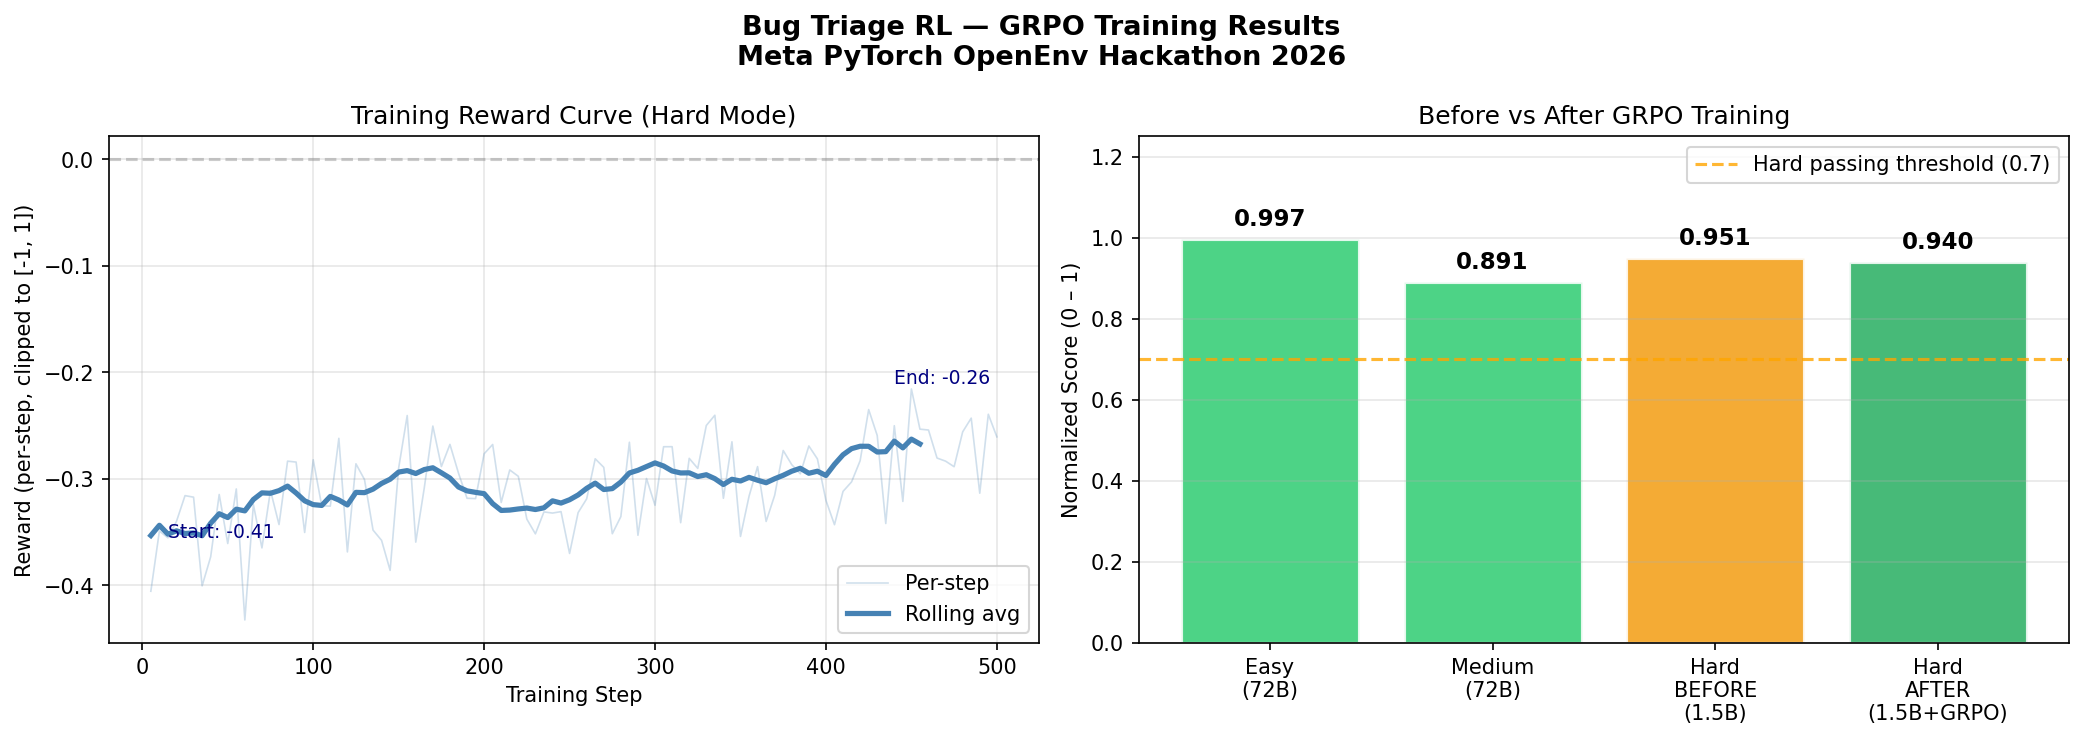

In [11]:
import base64
from IPython.display import HTML, display

with open('grpo_training_results.png', 'rb') as f:
    b64 = base64.b64encode(f.read()).decode()

display(HTML(f'<img src="data:image/png;base64,{b64}" style="max-width:100%"/>'))